# BTP — Two cells, a cell-dependent repulsion, and the torque it actually exerts

An update of `BTP_version3_two_cell_walk.ipynb`. Same two cells, same shared Stokes solve, same contact repulsion, same closed box, same redirect-on-collision rule. What changes is the interaction, and only where the previous interaction could not do what the physics asks of it.

The previous repulsion, $k_{\rm rep}\int\phi_1^2\phi_2^2$, is zero until the two interfaces overlap. Raising $k_{\rm rep}$ makes that contact stiffer. It cannot steer either cell *before* they touch, however large it is. Avoidance needs a range. Torque needs a force that does not pass through the centre of mass. And this model has no inertia, so angular momentum is not a quantity the cell can store.

### Three choices, each made so the instruction is not fitted by hand

1. **No inertial angular momentum.** $Re\sim 10^{-5}$ and the Stokes equation has no $\partial_t\mathbf v$. The angular statement of that same approximation is an overdamped balance, not $I\dot\omega=\tau$:

$$\tau_i=\xi_{{\rm rot},i}\,\omega_i,\qquad
\xi_{{\rm rot},i}=\xi\int\phi_i\,|\mathbf r-\mathbf r_{{\rm cm},i}|^2\,dA,\qquad
\omega_i=\tau_i/\xi_{{\rm rot},i}.$$

The torque is handed to the substrate immediately, through the same friction $\xi$ that already balances the linear force. $\omega_i$ then rotates $\mathbf P$, in addition to the vorticity term that was already in Version 3. $\xi_{\rm rot}$ is computed from the cell's own shape. It is not a free parameter.

2. **A force along the line of centres does not torque a round cell.** $\tau_i=\int(\mathbf r-\mathbf r_{{\rm cm},i})\times\mathbf f_i^{\rm rep}\,dA$. For two circular cells the repulsion is a central force, so this integral is zero head-on *and* on an offset approach, until crawling or contact deforms the shape and the force no longer passes through the centre. Nothing in this notebook adds a torque by hand along the direction of motion. Head-on is the control: symmetry requires $\tau=0$, and the run below is where that is checked.

3. **Avoidance is scattering, not a new rule.** The new term is a screened repulsion of range $\lambda$, with a strength proportional to the product of a property of each cell — the same structure as $Gm_1m_2$:

$$q_i=c_i\frac{A_i}{A_0},\qquad A_i=\int\phi_i\,dA,\qquad A_0=\pi R_0^2,$$

$$\rho_i=\phi_i^2,\qquad (1-\lambda^2\nabla^2)\psi_i=\rho_i,$$

$$F_{\rm soft}=k_{\rm soft}\,q_1 q_2\int\rho_1\,\psi_2\,dA.$$

$c_i=1$ unless a cell is given a different cortical charge. Because $q_i$ tracks the area, a larger cell both sources and feels a stronger repulsion, and — since the force on the two cells is equal and opposite while the friction scales with area — the smaller cell is deflected more. If this force turns the path aside before the interfaces meet, there is no collision. If $k_{\rm soft}=0$, or the approach is dead centre and the propulsion wins, they meet, and the contact term plus the shared Stokes solve do what they did in the previous notebook, including the same redirect.

$\lambda=8$ and $k_{\rm soft}=15$ (with the previous $k_{\rm rep}=20$ left unchanged) were selected so that an offset of about one cell radius misses, while switching the long-range piece off still collides. They are not unique.

# 1. The Version 3 operators

Grid, derivatives, stresses, the spectral Stokes solve and the initial condition are unchanged from `BTP_version3.ipynb`. $dx=0.625$ is kept: a coarser grid under-resolves the $\varepsilon=1.5$ interface.

In [1]:
import os
import time
import numpy as np
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Video

os.makedirs("two_cell_scattering_media", exist_ok=True)

L = 120.0
N = int(round(L / 0.625))
R0 = 13.0
eps = 1.5
a_phi = 1.0
M_phi = 1.0
a_pol = 0.5
kappa = 1.0
Gamma = 1.0
chi = 1.1
eta = 1.0
xi = 1.0
dt = 0.01
A0 = np.pi * R0 ** 2

# contact repulsion, unchanged from the previous two-cell notebook
krep = 20.0
# long-range piece. lam_rep is the screening length of (1 - lam^2 laplacian)
k_soft = 15.0
lam_rep = 8.0

MOVE = dict(w0=1.0, zeta=-1.0, beta=0.25)
REST = dict(w0=0.0, zeta=0.0, beta=0.0)

print(f"grid {N} x {N},  dx = {L / N:.4f},  A0 = {A0:.1f}")

grid 192 x 192,  dx = 0.6250,  A0 = 530.9


In [2]:
def setup_grid():
    global dx, X, Y, KX, KY, K2, K2_safe
    dx = L / N
    coords = (np.arange(N) - N // 2) * dx
    X, Y = np.meshgrid(coords, coords, indexing="ij")
    k1 = 2.0 * np.pi * np.fft.fftfreq(N, d=dx)
    KX, KY = np.meshgrid(k1, k1, indexing="ij")
    K2 = KX ** 2 + KY ** 2
    K2_safe = K2.copy()
    K2_safe[0, 0] = 1.0


setup_grid()


def d_dx(a):
    return (np.roll(a, -1, axis=0) - np.roll(a, 1, axis=0)) / (2.0 * dx)


def d_dy(a):
    return (np.roll(a, -1, axis=1) - np.roll(a, 1, axis=1)) / (2.0 * dx)


def laplacian(a):
    return (np.roll(a, -1, axis=0) + np.roll(a, 1, axis=0)
            + np.roll(a, -1, axis=1) + np.roll(a, 1, axis=1)
            - 4.0 * a) / dx ** 2


def divergence_of_flux(phi, ux, uy):
    Fx = 0.5 * (phi + np.roll(phi, -1, axis=0)) * 0.5 * (ux + np.roll(ux, -1, axis=0))
    Fy = 0.5 * (phi + np.roll(phi, -1, axis=1)) * 0.5 * (uy + np.roll(uy, -1, axis=1))
    return ((Fx - np.roll(Fx, 1, axis=0)) + (Fy - np.roll(Fy, 1, axis=1))) / dx


def molecular_field_P(phi, Px, Py, P2, beta):
    bulk = -a_pol * (2.0 * phi - 1.0) + a_pol * P2
    hx = bulk * Px - kappa * laplacian(Px) + beta * d_dx(phi)
    hy = bulk * Py - kappa * laplacian(Py) + beta * d_dy(phi)
    return hx, hy


def body_force(phi, Px, Py, mu, hx, hy, zeta):
    Axx = -zeta * phi * Px * Px
    Axy = -zeta * phi * Px * Py
    Ayy = -zeta * phi * Py * Py
    torque = 0.5 * (Px * hy - Py * hx)
    Exx = -chi * Px * hx
    Exy = torque - 0.5 * chi * (Px * hy + Py * hx)
    Eyx = -torque - 0.5 * chi * (Py * hx + Px * hy)
    Eyy = -chi * Py * hy
    Pxx, Pxy = d_dx(Px), d_dy(Px)
    Pyx, Pyy = d_dx(Py), d_dy(Py)
    Kxx = -kappa * (Pxx * Pxx + Pyx * Pyx)
    Kxy = -kappa * (Pxx * Pxy + Pyx * Pyy)
    Kyy = -kappa * (Pxy * Pxy + Pyy * Pyy)
    Sxx, Sxy = Axx + Exx + Kxx, Axy + Exy + Kxy
    Syx, Syy = Axy + Eyx + Kxy, Ayy + Eyy + Kyy
    fx = d_dx(Sxx) + d_dy(Sxy) - phi * d_dx(mu)
    fy = d_dx(Syx) + d_dy(Syy) - phi * d_dy(mu)
    return fx, fy


def stokes_solve(fx, fy):
    fxh, fyh = np.fft.fft2(fx), np.fft.fft2(fy)
    longitudinal = (KX * fxh + KY * fyh) / K2_safe
    fxh = fxh - KX * longitudinal
    fyh = fyh - KY * longitudinal
    screened_k = xi + eta * K2
    vxh, vyh = fxh / screened_k, fyh / screened_k
    vxh[0, 0] = vyh[0, 0] = 0.0
    return np.real(np.fft.ifft2(vxh)), np.real(np.fft.ifft2(vyh))


def init_cell(cx, cy, radius=R0):
    r = np.sqrt((X - cx) ** 2 + (Y - cy) ** 2)
    phi = 0.5 * (1.0 - np.tanh((r - radius) / (np.sqrt(2.0) * eps)))
    return phi, np.zeros_like(phi), np.zeros_like(phi)


def centre_of_mass(phi):
    m = phi.sum()
    return (X * phi).sum() / m, (Y * phi).sum() / m


def polarity_stats(phi, Px, Py):
    # angle and magnitude of the mean polarity, and the mean of the local magnitude.
    # |<P>| falling while <|P|> stays high means the polarity splayed; both falling
    # means it depolarized.
    w = phi.sum()
    mx = (phi * Px).sum() / w
    my = (phi * Py).sum() / w
    local = (phi * np.hypot(Px, Py)).sum() / w
    return np.degrees(np.arctan2(my, mx)), np.hypot(mx, my), local


def circularity(phi):
    inside = phi > 0.5
    area = inside.sum() * dx ** 2
    gx, gy = d_dx(phi), d_dy(phi)
    perimeter = np.sqrt(gx ** 2 + gy ** 2).sum() * dx ** 2
    return 4.0 * np.pi * area / max(perimeter ** 2, 1e-12)

# 2. The repulsion, the charge, and the torque

The chemical potential added to cell $i$ by both pieces of the repulsion is

$$\mu_i^{\rm rep}=2k_{\rm rep}\,\phi_i\phi_j^2+2k_{\rm soft}\,q_i q_j\,\phi_i\psi_j.$$

Both terms already contain a factor of $\phi_i$, so they vanish outside the cell and can sit in the relaxation equation without the empty-space sink that the first attempt at a wall potential produced. The same $\mu^{\rm rep}$ enters the capillary force $-\phi\nabla\mu$ inside the one shared Stokes solve, which is what actually pushes the centres. The torque and $\omega$ below are computed from that steric force alone, not from the cell's own active stress.

The wall potential is the one from the previous notebook, and it is still added only to the $\mu$ seen by the force.

In [3]:
wall_margin = 16.0
k_wall = 0.01
dx_edge = np.maximum(0.0, np.abs(X) - (L / 2 - wall_margin))
dy_edge = np.maximum(0.0, np.abs(Y) - (L / 2 - wall_margin))
U_WALL = k_wall * (dx_edge ** 2 + dy_edge ** 2)
print(f"U_WALL max = {U_WALL.max():.2f}, zero over {100 * (U_WALL == 0).mean():.0f}% of the box")


def screened(rho, lam):
    # (1 - lam^2 laplacian) psi = rho, solved in Fourier space.
    psi_h = np.fft.fft2(rho) / (1.0 + (lam ** 2) * K2)
    return np.real(np.fft.ifft2(psi_h))


def charge_of(phi, factor):
    return factor * (phi.sum() * dx * dx) / A0


def rep_mu(phi, phi_other, q_self, q_other, ksoft, lam):
    contact = 2.0 * krep * phi * phi_other ** 2
    if ksoft == 0.0:
        return contact
    psi_other = screened(phi_other ** 2, lam)
    return contact + 2.0 * ksoft * q_self * q_other * phi * psi_other


def steric_torque(phi, mu_rep):
    # overdamped balance: tau = xi_rot * omega, xi_rot from the substrate friction.
    cx, cy = centre_of_mass(phi)
    fx = -phi * d_dx(mu_rep)
    fy = -phi * d_dy(mu_rep)
    rx, ry = X - cx, Y - cy
    tau = (rx * fy - ry * fx).sum() * dx * dx
    xi_rot = xi * (phi * (rx ** 2 + ry ** 2)).sum() * dx * dx
    omega = tau / xi_rot
    Fx = fx.sum() * dx * dx
    Fy = fy.sum() * dx * dx
    return tau, omega, xi_rot, Fx, Fy


def mu_phi(phi, P2, dPx_dx, dPy_dy, beta, mu_rep):
    return (2.0 * a_phi * phi * (phi - 1.0) * (2.0 * phi - 1.0)
            - eps ** 2 * laplacian(phi) - a_pol * P2 - beta * (dPx_dx + dPy_dy)
            + mu_rep)


def advance_one(phi, Px, Py, mu, hx, hy, vx, vy, w0_now, omega_rigid):
    ux, uy = vx + w0_now * Px, vy + w0_now * Py
    g = np.clip(phi * (1.0 - phi), 0.0, None)
    Lagrange = mu.sum() / g.sum()
    phi_new = phi + dt * (-divergence_of_flux(phi, ux, uy) - M_phi * (mu - Lagrange * g))

    dvx_dx, dvx_dy = d_dx(vx), d_dy(vx)
    dvy_dx, dvy_dy = d_dx(vy), d_dy(vy)
    Dxx, Dyy = dvx_dx, dvy_dy
    Dxy = 0.5 * (dvx_dy + dvy_dx)
    omega_flow = 0.5 * (dvy_dx - dvx_dy)

    adv_Px = ux * d_dx(Px) + uy * d_dy(Px)
    adv_Py = ux * d_dx(Py) + uy * d_dy(Py)
    # omega_flow is the local fluid rotation (Version 3). omega_rigid is the
    # single scalar from tau/xi_rot. They are different channels.
    Px_new = Px + dt * (-adv_Px - (omega_flow + omega_rigid) * Py
                        + chi * (Dxx * Px + Dxy * Py) - hx / Gamma)
    Py_new = Py + dt * (-adv_Py + (omega_flow + omega_rigid) * Px
                        + chi * (Dxy * Px + Dyy * Py) - hy / Gamma)
    return phi_new, Px_new, Py_new


def step_both(phi1, Px1, Py1, phi2, Px2, Py2, params1, params2,
              ksoft, lam, c1, c2):
    q1, q2 = charge_of(phi1, c1), charge_of(phi2, c2)
    mu_r1 = rep_mu(phi1, phi2, q1, q2, ksoft, lam)
    mu_r2 = rep_mu(phi2, phi1, q2, q1, ksoft, lam)
    P2_1, P2_2 = Px1 ** 2 + Py1 ** 2, Px2 ** 2 + Py2 ** 2
    mu1 = mu_phi(phi1, P2_1, d_dx(Px1), d_dy(Py1), params1["beta"], mu_r1)
    mu2 = mu_phi(phi2, P2_2, d_dx(Px2), d_dy(Py2), params2["beta"], mu_r2)
    hx1, hy1 = molecular_field_P(phi1, Px1, Py1, P2_1, params1["beta"])
    hx2, hy2 = molecular_field_P(phi2, Px2, Py2, P2_2, params2["beta"])
    # wall potential joins the chemical potential only inside the force
    fx1, fy1 = body_force(phi1, Px1, Py1, mu1 + U_WALL, hx1, hy1, params1["zeta"])
    fx2, fy2 = body_force(phi2, Px2, Py2, mu2 + U_WALL, hx2, hy2, params2["zeta"])
    vx, vy = stokes_solve(fx1 + fx2, fy1 + fy2)
    tau1, w1, g1, Fx1, Fy1 = steric_torque(phi1, mu_r1)
    tau2, w2, g2, Fx2, Fy2 = steric_torque(phi2, mu_r2)
    phi1n, Px1n, Py1n = advance_one(
        phi1, Px1, Py1, mu1, hx1, hy1, vx, vy, params1["w0"], w1)
    phi2n, Px2n, Py2n = advance_one(
        phi2, Px2, Py2, mu2, hx2, hy2, vx, vy, params2["w0"], w2)
    info = dict(tau1=tau1, tau2=tau2, w1=w1, w2=w2, xi1=g1, xi2=g2,
                Fx1=Fx1, Fy1=Fy1, Fx2=Fx2, Fy2=Fy2, q1=q1, q2=q2)
    return phi1n, Px1n, Py1n, phi2n, Px2n, Py2n, info

U_WALL max = 5.12, zero over 54% of the box


In [4]:
def composite_rgb(phi1, phi2):
    absorb1 = np.array([0.77, 0.52, 0.17])
    absorb2 = np.array([0.17, 0.67, 0.77])
    img = (1.0 - np.clip(phi1, 0, 1)[..., None] * absorb1
               - np.clip(phi2, 0, 1)[..., None] * absorb2)
    return np.clip(img, 0, 1)


def draw_arrows(ax, phi, Px, Py, color, stride=8):
    mask = phi > 0.3
    scale = 14.0 * (np.hypot(Px, Py).max() + 1e-12)
    ax.quiver(X[::stride, ::stride], Y[::stride, ::stride],
              np.where(mask, Px, 0.0)[::stride, ::stride],
              np.where(mask, Py, 0.0)[::stride, ::stride],
              color=color, scale=scale, width=0.0045)


def run_pair(y0, ksoft, nsteps, radius2=R0, charge1=1.0, charge2=1.0,
             beta=0.25, sample_every=50, frame_every=100, x0=22.0):
    # Both cells crawl toward each other along x, with a vertical offset y0
    # (y0 = 0 is head-on). Headings are not reset: whatever they do is the dynamics.
    params = dict(w0=MOVE["w0"], zeta=MOVE["zeta"], beta=beta)
    phi1, Px1, Py1 = init_cell(-x0, -y0 / 2.0)
    phi2, Px2, Py2 = init_cell(x0, y0 / 2.0, radius=radius2)
    Px1[phi1 > 1e-3] = 1.0
    Px2[phi2 > 1e-3] = -1.0

    keys = ["time", "sep", "overlap", "angle1", "angle2", "mean1", "mean2",
            "local1", "local2", "tau1", "tau2", "omega_deg1", "omega_deg2",
            "x1", "y1", "x2", "y2", "area1", "area2", "q1", "q2"]
    hist = {k: [] for k in keys}
    frames = []
    ang_w1 = 0.0
    ang_w2 = 0.0
    t0 = time.time()
    for s in range(nsteps):
        phi1, Px1, Py1, phi2, Px2, Py2, info = step_both(
            phi1, Px1, Py1, phi2, Px2, Py2, params, params,
            ksoft, lam_rep, charge1, charge2)
        if not (np.isfinite(phi1).all() and np.isfinite(phi2).all()):
            print(f"diverged at step {s}")
            break
        ang_w1 += info["w1"] * dt
        ang_w2 += info["w2"] * dt
        if frame_every and s % frame_every == 0:
            frames.append((s * dt, phi1.copy(), Px1.copy(), Py1.copy(),
                           phi2.copy(), Px2.copy(), Py2.copy()))
        if s % sample_every == 0:
            x1, y1 = centre_of_mass(phi1)
            x2, y2 = centre_of_mass(phi2)
            a1, m1, loc1 = polarity_stats(phi1, Px1, Py1)
            a2, m2, loc2 = polarity_stats(phi2, Px2, Py2)
            row = dict(
                time=s * dt, sep=float(np.hypot(x2 - x1, y2 - y1)),
                overlap=(phi1 * phi2).sum() * dx * dx,
                angle1=a1, angle2=a2, mean1=m1, mean2=m2, local1=loc1, local2=loc2,
                tau1=info["tau1"], tau2=info["tau2"],
                omega_deg1=np.degrees(ang_w1), omega_deg2=np.degrees(ang_w2),
                x1=x1, y1=y1, x2=x2, y2=y2,
                area1=phi1.sum() * dx * dx, area2=phi2.sum() * dx * dx,
                q1=info["q1"], q2=info["q2"])
            for k in keys:
                hist[k].append(row[k])
    elapsed = time.time() - t0
    diag = {k: np.array(v) for k, v in hist.items()}
    diag["ms_per_step"] = 1000.0 * elapsed / max(s, 1)
    diag["radius2"] = radius2
    return diag, frames


def summarize(name, diag):
    contact = R0 + diag["radius2"]
    print(f"{name}")
    print(f"  {diag['ms_per_step']:.1f} ms/step")
    print(f"  min separation {diag['sep'].min():.2f}   (interfaces meet near {contact:.1f})")
    print(f"  max overlap    {diag['overlap'].max():.3f}")
    print(f"  heading 1  {diag['angle1'][0]:+7.2f} -> {diag['angle1'][-1]:+7.2f} deg"
          f"     |<P>| {diag['mean1'][0]:.3f} -> {diag['mean1'][-1]:.3f}"
          f"     <|P|> {diag['local1'][0]:.3f} -> {diag['local1'][-1]:.3f}")
    print(f"  heading 2  {diag['angle2'][0]:+7.2f} -> {diag['angle2'][-1]:+7.2f} deg"
          f"     |<P>| {diag['mean2'][0]:.3f} -> {diag['mean2'][-1]:.3f}"
          f"     <|P|> {diag['local2'][0]:.3f} -> {diag['local2'][-1]:.3f}")
    print(f"  rigid rotation from tau/xi_rot:  cell 1 {diag['omega_deg1'][-1]:+.3f} deg,"
          f"  cell 2 {diag['omega_deg2'][-1]:+.3f} deg")
    print(f"  peak |torque|  cell 1 {np.max(np.abs(diag['tau1'])):.2f}"
          f"    cell 2 {np.max(np.abs(diag['tau2'])):.2f}")
    print(f"  area  cell 1 {diag['area1'][0]:.2f} -> {diag['area1'][-1]:.2f}"
          f"    cell 2 {diag['area2'][0]:.2f} -> {diag['area2'][-1]:.2f}")
    print(f"  charge q  cell 1 {diag['q1'][0]:.3f} -> {diag['q1'][-1]:.3f}"
          f"    cell 2 {diag['q2'][0]:.3f} -> {diag['q2'][-1]:.3f}")
    for which, mean in (("cell 1", diag["mean1"][-1]), ("cell 2", diag["mean2"][-1])):
        if mean < 0.15:
            print(f"  ({which} final |<P>| is {mean:.3f}: the heading angle is the"
                  f" direction of a weak residual, not an ordered crawl)")


def plot_run(diag, stem, title):
    fig, ax = plt.subplots(1, 3, figsize=(13.2, 3.8))
    ax[0].plot(diag["x1"], diag["y1"], color="tab:blue", label="cell 1")
    ax[0].plot(diag["x2"], diag["y2"], color="tab:red", label="cell 2")
    ax[0].scatter([diag["x1"][0], diag["x2"][0]], [diag["y1"][0], diag["y2"][0]],
                  c=["tab:blue", "tab:red"], zorder=3)
    ax[0].set_aspect("equal")
    ax[0].set_xlabel("x")
    ax[0].set_ylabel("y")
    ax[0].set_title("centres of mass")
    ax[0].legend(fontsize=8)
    ax[1].plot(diag["time"], diag["sep"], color="k", label="separation")
    ax[1].axhline(R0 + diag["radius2"], color="gray", ls="--", lw=1, label="nominal contact")
    ax[1].set_xlabel("t")
    ax[1].set_ylabel("separation")
    # an overlap of 1e-5 is the phase field sitting slightly off zero, not a contact
    if np.max(np.abs(diag["overlap"])) > 0.05:
        ax1b = ax[1].twinx()
        ax1b.plot(diag["time"], diag["overlap"], color="tab:purple", alpha=0.85)
        ax1b.set_ylabel("overlap", color="tab:purple")
    ax[1].legend(fontsize=8, loc="best")
    # unwrap so a heading sitting near ±180 does not draw a fake jump
    ang1 = np.degrees(np.unwrap(np.radians(diag["angle1"])))
    ang2 = np.degrees(np.unwrap(np.radians(diag["angle2"])))
    ax[2].plot(diag["time"], ang1, color="tab:blue", label="heading 1")
    ax[2].plot(diag["time"], ang2, color="tab:red", label="heading 2")
    ax[2].plot(diag["time"], diag["omega_deg1"], color="tab:blue", ls="--",
               label="rigid rotation 1")
    ax[2].set_xlabel("t")
    ax[2].set_ylabel("degrees")
    ax[2].set_title("heading, and the rigid rotation from torque")
    ax[2].legend(fontsize=7)
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    path = f"two_cell_scattering_media/{stem}.png"
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()
    return path


def save_video(frames, path, title, xlim=(-45, 45), ylim=(-40, 40), seconds=4.5):
    fig, ax = plt.subplots(figsize=(6.0, 5.6))

    def render(i):
        ax.clear()
        t, f1, p1x, p1y, f2, p2x, p2y = frames[i]
        img = composite_rgb(f1, f2)
        ax.imshow(img.transpose(1, 0, 2), origin="lower",
                  extent=[-L / 2, L / 2, -L / 2, L / 2])
        draw_arrows(ax, f1, p1x, p1y, "navy", stride=6)
        draw_arrows(ax, f2, p2x, p2y, "darkred", stride=6)
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_aspect("equal")
        ax.set_title(f"{title}     t = {t:5.1f}")

    render(0)
    fig.tight_layout()
    ani = animation.FuncAnimation(fig, lambda i: render(i) or [],
                                  frames=len(frames), blit=False)
    fps = max(1, round(len(frames) / seconds))
    ani.save(path, writer=animation.FFMpegWriter(fps=fps, bitrate=2400))
    plt.close(fig)
    print(f"saved {path}: {len(frames)} frames, {fps} fps, {len(frames) / fps:.1f} s")
    return path

# 3. Static check, before any crawling

Two round cells, held fixed. This is only the force law: action–reaction, the product $q_1 q_2$, and a torque that must be zero while the cells are round.

In [5]:
def static_case(label, y2, ksoft, c2):
    p1, _, _ = init_cell(-18.0, 0.0)
    p2, _, _ = init_cell(18.0, y2)
    q1, q2 = charge_of(p1, 1.0), charge_of(p2, c2)
    mr1 = rep_mu(p1, p2, q1, q2, ksoft, lam_rep)
    mr2 = rep_mu(p2, p1, q2, q1, ksoft, lam_rep)
    t1, w1, g1, Fx1, Fy1 = steric_torque(p1, mr1)
    t2, w2, g2, Fx2, Fy2 = steric_torque(p2, mr2)
    ov = (p1 * p2).sum() * dx * dx
    print(f"{label}")
    print(f"  overlap {ov:.4f}   q = ({q1:.3f}, {q2:.3f})")
    print(f"  F1 = ({Fx1:9.3f}, {Fy1:9.3f})   F2 = ({Fx2:9.3f}, {Fy2:9.3f})"
          f"   sum = ({Fx1 + Fx2:8.2e}, {Fy1 + Fy2:8.2e})")
    print(f"  tau = ({t1:8.2e}, {t2:8.2e})    xi_rot = {g1:.1f}")


static_case("contact term only, offset by 6", y2=6.0, ksoft=0.0, c2=1.0)
static_case("long-range on, equal cells, offset by 6", y2=6.0, ksoft=k_soft, c2=1.0)
static_case("long-range on, cell 2 charge doubled, same shapes", y2=6.0, ksoft=k_soft, c2=2.0)
static_case("long-range on, head-on", y2=0.0, ksoft=k_soft, c2=1.0)

contact term only, offset by 6
  overlap 0.0044   q = (1.022, 1.022)
  F1 = (   -0.000,    -0.000)   F2 = (    0.000,     0.000)   sum = (-1.69e-21, -2.12e-22)
  tau = (6.47e-07, 6.47e-07)    xi_rot = 50849.0
long-range on, equal cells, offset by 6
  overlap 0.0044   q = (1.022, 1.022)
  F1 = (  -11.696,    -1.957)   F2 = (   11.696,     1.957)   sum = (-2.04e-11, -9.44e-13)
  tau = (-1.28e-02, -1.28e-02)    xi_rot = 50849.0
long-range on, cell 2 charge doubled, same shapes
  overlap 0.0044   q = (1.022, 2.044)
  F1 = (  -23.393,    -3.913)   F2 = (   23.393,     3.913)   sum = (-4.08e-11, -1.89e-12)
  tau = (-2.56e-02, -2.56e-02)    xi_rot = 50849.0
long-range on, head-on
  overlap 0.0066   q = (1.022, 1.022)
  F1 = (  -12.716,     0.000)   F2 = (   12.716,    -0.000)   sum = (-1.60e-14, -1.43e-16)
  tau = (1.59e-15, -1.24e-15)    xi_rot = 50849.0


# 4. Offset approach, long-range repulsion on

Both cells crawl toward each other (fixed initial headings $\mathbf P=\hat x$ and $-\hat x$, then left to the dynamics) with the centres offset by 10. The dashed curve in the third panel is $\int\omega\,dt$ from $\omega=\tau/\xi_{\rm rot}$. If the heading moves by a lot more than that curve, the turn is not the rigid rotation.

offset, k_soft = 15
  12.1 ms/step
  min separation 36.80   (interfaces meet near 26.0)
  max overlap    0.000
  heading 1    -0.00 ->  -34.84 deg     |<P>| 0.998 -> 0.891     <|P|> 0.998 -> 0.951
  heading 2  +180.00 -> +145.16 deg     |<P>| 0.998 -> 0.891     <|P|> 0.998 -> 0.951
  rigid rotation from tau/xi_rot:  cell 1 +0.276 deg,  cell 2 +0.276 deg
  peak |torque|  cell 1 18.72    cell 2 18.72
  area  cell 1 542.56 -> 542.56    cell 2 542.56 -> 542.56
  charge q  cell 1 1.022 -> 1.022    cell 2 1.022 -> 1.022


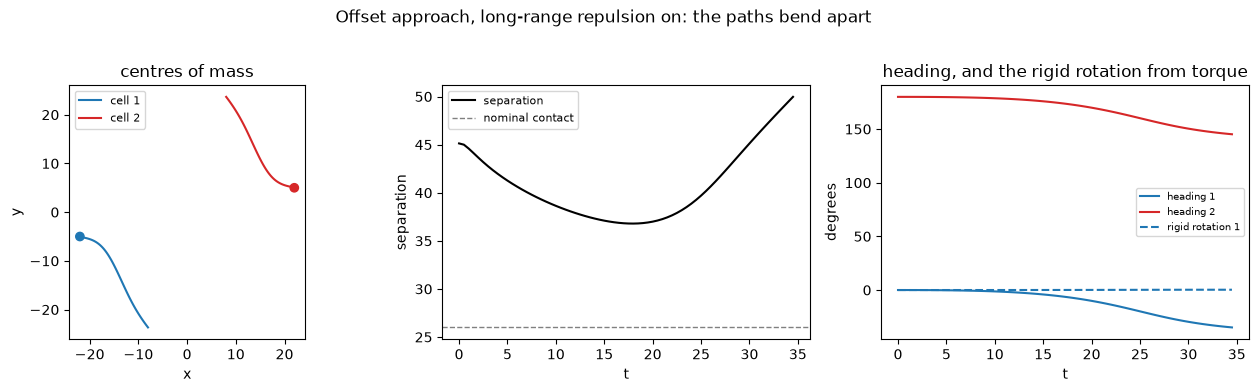

'two_cell_scattering_media/offset_avoidance.png'

In [6]:
avoid, avoid_frames = run_pair(y0=10.0, ksoft=k_soft, nsteps=3500, frame_every=100)
summarize("offset, k_soft = 15", avoid)
plot_run(avoid, "offset_avoidance", "Offset approach, long-range repulsion on: the paths bend apart")

In [7]:
avoid_video = save_video(
    avoid_frames, "two_cell_scattering_media/offset_avoidance.mp4",
    "offset approach, long-range repulsion on")
Video(avoid_video, embed=True, width=480)

saved two_cell_scattering_media/offset_avoidance.mp4: 35 frames, 8 fps, 4.4 s


# 5. Where the heading change comes from

Same initial condition and the same repulsion, with anchoring switched off ($\beta=0$). The rigid-rotation channel is still on. If the heading change in Section 4 was the torque spinning the cell, it survives here. If it was anchoring — $\mathbf P$ kept normal to an edge the repulsion has deformed — it does not.

In [8]:
no_anchor, _ = run_pair(y0=10.0, ksoft=k_soft, nsteps=2500,
                        beta=0.0, frame_every=0)
summarize("offset, k_soft = 15, anchoring off", no_anchor)
print()
print("heading change with anchoring   ",
      f"{avoid['angle1'][avoid['time'] <= 24][-1] - avoid['angle1'][0]:+.2f} deg at t<=24")
print("heading change without anchoring",
      f"{no_anchor['angle1'][-1] - no_anchor['angle1'][0]:+.2f} deg")
print("of which the rigid rotation is ",
      f"{no_anchor['omega_deg1'][-1]:+.3f} deg")

offset, k_soft = 15, anchoring off
  12.0 ms/step
  min separation 36.40   (interfaces meet near 26.0)
  max overlap    0.000
  heading 1    -0.00 ->   -0.43 deg     |<P>| 0.998 -> 0.820     <|P|> 0.998 -> 0.821
  heading 2  +180.00 -> +179.57 deg     |<P>| 0.998 -> 0.820     <|P|> 0.998 -> 0.821
  rigid rotation from tau/xi_rot:  cell 1 +0.068 deg,  cell 2 +0.068 deg
  peak |torque|  cell 1 6.87    cell 2 6.87
  area  cell 1 542.56 -> 542.56    cell 2 542.56 -> 542.56
  charge q  cell 1 1.022 -> 1.022    cell 2 1.022 -> 1.022

heading change with anchoring    -17.70 deg at t<=24
heading change without anchoring -0.43 deg
of which the rigid rotation is  +0.068 deg


# 6. The same approach with the long-range piece switched off

$k_{\rm soft}=0$, contact term and shared Stokes solve exactly as in the previous notebook, same offset. This is the collision the long-range term was avoiding. Headings are still not being reassigned by the decision layer, so the rotation here is the contact itself.

offset, k_soft = 0 (contact term only)
  10.4 ms/step
  min separation 18.25   (interfaces meet near 26.0)
  max overlap    3.913
  heading 1    -0.00 ->  -15.71 deg     |<P>| 0.998 -> 0.883     <|P|> 0.998 -> 0.941
  heading 2  +180.00 -> +164.29 deg     |<P>| 0.998 -> 0.883     <|P|> 0.998 -> 0.941
  rigid rotation from tau/xi_rot:  cell 1 +1.913 deg,  cell 2 +1.913 deg
  peak |torque|  cell 1 158.28    cell 2 158.28
  area  cell 1 542.56 -> 542.56    cell 2 542.56 -> 542.56
  charge q  cell 1 1.022 -> 1.022    cell 2 1.022 -> 1.022


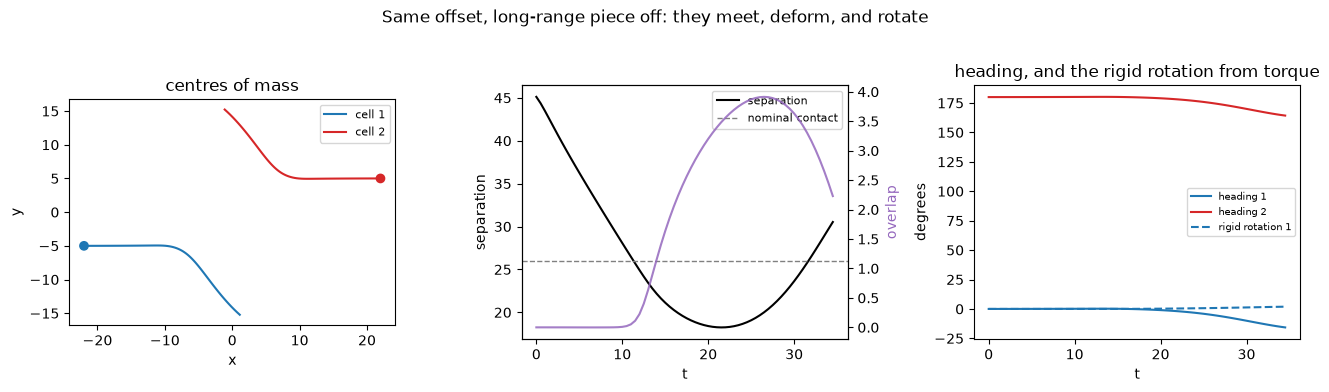

'two_cell_scattering_media/offset_collision.png'

In [9]:
hit, hit_frames = run_pair(y0=10.0, ksoft=0.0, nsteps=3500, frame_every=100)
summarize("offset, k_soft = 0 (contact term only)", hit)
plot_run(hit, "offset_collision", "Same offset, long-range piece off: they meet, deform, and rotate")

In [10]:
hit_video = save_video(
    hit_frames, "two_cell_scattering_media/offset_collision.mp4",
    "offset approach, contact repulsion only")
Video(hit_video, embed=True, width=480)

saved two_cell_scattering_media/offset_collision.mp4: 35 frames, 8 fps, 4.4 s


# 7. Head-on, where a torque is forbidden

Same repulsion as Section 4, offset removed. Symmetry puts both the force and the heading on the $x$-axis, so $\tau$ has to stay zero and the heading cannot rotate off the axis. What the centres do, and what happens to $|\langle\mathbf P\rangle|$ as against the local $\langle|\mathbf P|\rangle$, is the content of the run. A falling mean with a healthy local magnitude would be a splay; both falling is a real loss of order.

head-on, k_soft = 15
  11.8 ms/step
  min separation 28.73   (interfaces meet near 26.0)
  max overlap    0.000
  heading 1    +0.00 -> +180.00 deg     |<P>| 0.998 -> 0.064     <|P|> 0.998 -> 0.845
  heading 2  -180.00 ->   +0.00 deg     |<P>| 0.998 -> 0.064     <|P|> 0.998 -> 0.845
  rigid rotation from tau/xi_rot:  cell 1 -0.000 deg,  cell 2 +0.000 deg
  peak |torque|  cell 1 0.00    cell 2 0.00
  area  cell 1 542.56 -> 542.56    cell 2 542.56 -> 542.56
  charge q  cell 1 1.022 -> 1.022    cell 2 1.022 -> 1.022
  (cell 1 final |<P>| is 0.064: the heading angle is the direction of a weak residual, not an ordered crawl)
  (cell 2 final |<P>| is 0.064: the heading angle is the direction of a weak residual, not an ordered crawl)


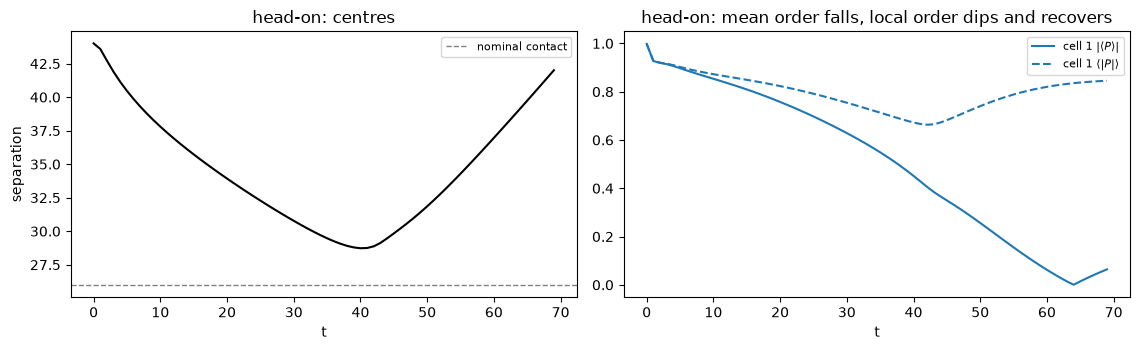

torque over the whole run: max |tau1| = 9.995e-07, max |tau2| = 9.995e-07


In [11]:
head, _ = run_pair(y0=0.0, ksoft=k_soft, nsteps=7000, frame_every=0, sample_every=100)
summarize("head-on, k_soft = 15", head)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax[0].plot(head["time"], head["sep"], color="k")
ax[0].axhline(2 * R0, color="gray", ls="--", lw=1, label="nominal contact")
ax[0].set_xlabel("t")
ax[0].set_ylabel("separation")
ax[0].legend(fontsize=8)
ax[0].set_title("head-on: centres")
ax[1].plot(head["time"], head["mean1"], color="tab:blue", label=r"cell 1 $|\langle P\rangle|$")
ax[1].plot(head["time"], head["local1"], color="tab:blue", ls="--", label=r"cell 1 $\langle|P|\rangle$")
ax[1].set_xlabel("t")
ax[1].set_ylim(-0.05, 1.05)
ax[1].legend(fontsize=8)
ax[1].set_title(r"head-on: mean order falls, local order dips and recovers")
fig.tight_layout()
fig.savefig("two_cell_scattering_media/headon.png", dpi=140, bbox_inches="tight")
plt.show()
print(f"torque over the whole run: max |tau1| = {np.max(np.abs(head['tau1'])):.3e},"
      f" max |tau2| = {np.max(np.abs(head['tau2'])):.3e}")

# 8. The repulsion depends on the cell

Same approach as Section 4, but cell 2 is grown from $R=9$ instead of $R=13$. Its charge $q_2=A_2/A_0$ is smaller because its area is smaller, and its friction is smaller for the same reason. The force on the two cells is still equal and opposite — that is action–reaction, and it does not care which cell is larger — so the smaller cell, being easier to push and easier to reorient, should be the one whose path and heading change more.

offset, cell 2 grown at R = 9
  11.9 ms/step
  min separation 29.46   (interfaces meet near 22.0)
  max overlap    0.000
  heading 1    -0.00 ->  -12.15 deg     |<P>| 0.998 -> 0.884     <|P|> 0.998 -> 0.931
  heading 2  +180.00 -> +135.46 deg     |<P>| 0.997 -> 0.704     <|P|> 0.997 -> 0.748
  rigid rotation from tau/xi_rot:  cell 1 +0.231 deg,  cell 2 +0.127 deg
  peak |torque|  cell 1 15.55    cell 2 2.96
  area  cell 1 542.56 -> 542.56    cell 2 266.09 -> 266.09
  charge q  cell 1 1.022 -> 1.022    cell 2 0.501 -> 0.501


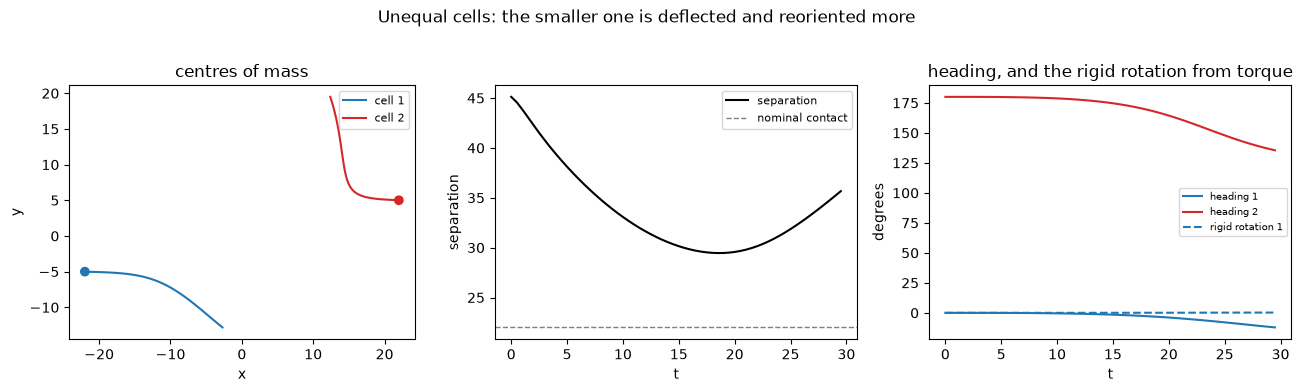

'two_cell_scattering_media/unequal_cells.png'

In [12]:
unequal, unequal_frames = run_pair(
    y0=10.0, ksoft=k_soft, nsteps=3000, radius2=9.0, frame_every=100)
summarize("offset, cell 2 grown at R = 9", unequal)
plot_run(unequal, "unequal_cells", "Unequal cells: the smaller one is deflected and reoriented more")

In [13]:
unequal_video = save_video(
    unequal_frames, "two_cell_scattering_media/unequal_cells.mp4",
    "unequal cells (cell 2 is the smaller)")
Video(unequal_video, embed=True, width=480)

saved two_cell_scattering_media/unequal_cells.mp4: 30 frames, 7 fps, 4.3 s


# 9. The walk, with this interaction

The decide → move → relax cycle and the redirect are the ones from `BTP_version3_two_cell_walk.ipynb`, unchanged in policy: a cell ends its move early and later draws a new heading if it has covered its distance, walked into the wall margin, or if the overlap integral crosses 1.5. The only thing underneath is the new `step_both`.

With $k_{\rm soft}=15$ the opening approach is the offset geometry of Section 4, so the expected first event is a miss rather than a redirect. The redirect is still there for an approach that does get through.

In [14]:
def run_two_cell_walk(d0=55.0, dy0=10.0, ksoft=k_soft,
                      distance_range=(15.0, 30.0),
                      relax_time=20.0, relax_time_cap=45.0, relax_circ_target=0.90,
                      wall_margin_redirect=25.0, collision_overlap_trigger=1.5,
                      t_final=50.0, sample_every=100, frame_every=250,
                      seed=7, max_steps_per_phase=12000):
    rng = np.random.default_rng(seed)
    phi1, Px1, Py1 = init_cell(-d0 / 2, -dy0 / 2)
    phi2, Px2, Py2 = init_cell(d0 / 2, dy0 / 2)

    def start_move(phi, theta, t_now, cycles_done):
        x0, y0 = centre_of_mass(phi)
        target = float(rng.uniform(*distance_range))
        return (phi * np.cos(theta), phi * np.sin(theta),
                dict(phase="move", target=target, x0=x0, y0=y0,
                     t0=t_now, phase_step=0, cycles_done=cycles_done))

    theta1_0 = np.arctan2(dy0, d0)
    Px1, Py1, s1 = start_move(phi1, theta1_0, 0.0, 0)
    Px2, Py2, s2 = start_move(phi2, theta1_0 + np.pi, 0.0, 0)

    keys = ["time", "x1", "y1", "x2", "y2", "overlap", "angle1", "angle2",
            "tau1", "tau2"]
    hist = {k: [] for k in keys}
    hist["phase1"] = []
    hist["phase2"] = []
    frames = []
    n_collisions = 0
    t0 = time.time()
    nsteps = int(round(t_final / dt))
    for step in range(1, nsteps + 1):
        p1 = MOVE if s1["phase"] == "move" else REST
        p2 = MOVE if s2["phase"] == "move" else REST
        phi1, Px1, Py1, phi2, Px2, Py2, info = step_both(
            phi1, Px1, Py1, phi2, Px2, Py2, p1, p2, ksoft, lam_rep, 1.0, 1.0)
        s1["phase_step"] += 1
        s2["phase_step"] += 1
        if not (np.isfinite(phi1).all() and np.isfinite(phi2).all()):
            print(f"diverged at t = {step * dt:.2f}")
            break
        t = step * dt
        if step % frame_every == 0:
            frames.append((t, phi1.copy(), Px1.copy(), Py1.copy(),
                           phi2.copy(), Px2.copy(), Py2.copy(),
                           s1["phase"], s2["phase"]))
        if step % sample_every == 0:
            x1, y1 = centre_of_mass(phi1)
            x2, y2 = centre_of_mass(phi2)
            overlap = (phi1 * phi2).sum() * dx * dx
            collision = overlap > collision_overlap_trigger
            if collision:
                n_collisions += 1
            a1, _, _ = polarity_stats(phi1, Px1, Py1)
            a2, _, _ = polarity_stats(phi2, Px2, Py2)
            hist["time"].append(t)
            hist["x1"].append(x1); hist["y1"].append(y1)
            hist["x2"].append(x2); hist["y2"].append(y2)
            hist["overlap"].append(overlap)
            hist["angle1"].append(a1); hist["angle2"].append(a2)
            hist["tau1"].append(info["tau1"]); hist["tau2"].append(info["tau2"])
            hist["phase1"].append(s1["phase"]); hist["phase2"].append(s2["phase"])
            for s, phi, which, x, y in ((s1, phi1, 1, x1, y1), (s2, phi2, 2, x2, y2)):
                near_wall = (L / 2 - max(abs(x), abs(y))) < wall_margin_redirect
                if s["phase"] == "move":
                    travelled = np.hypot(x - s["x0"], y - s["y0"])
                    if (travelled >= s["target"] or collision or near_wall
                            or s["phase_step"] >= max_steps_per_phase):
                        s["phase"] = "relax"
                        s["t0"] = t
                        s["phase_step"] = 0
                else:
                    elapsed = t - s["t0"]
                    if (elapsed >= relax_time_cap
                            or (elapsed >= relax_time and circularity(phi) >= relax_circ_target)
                            or s["phase_step"] >= max_steps_per_phase):
                        theta = float(rng.uniform(0.0, 2.0 * np.pi))
                        Px_new = phi * np.cos(theta)
                        Py_new = phi * np.sin(theta)
                        if which == 1:
                            Px1, Py1 = Px_new, Py_new
                        else:
                            Px2, Py2 = Px_new, Py_new
                        s.update(phase="move", target=float(rng.uniform(*distance_range)),
                                 x0=x, y0=y, t0=t, phase_step=0,
                                 cycles_done=s["cycles_done"] + 1)
            if step % (sample_every * 10) == 0:
                print(f"t={t:6.1f}  c1[{s1['phase']:5s}] c2[{s2['phase']:5s}]"
                      f"  overlap={overlap:6.3f}  collision-samples={n_collisions}"
                      f"  sep={np.hypot(x2 - x1, y2 - y1):6.1f}")
    elapsed = time.time() - t0
    diag = {k: (np.array(v) if k not in ("phase1", "phase2") else v) for k, v in hist.items()}
    print(f"walk: {elapsed:.1f} s, max overlap {diag['overlap'].max():.3f},"
          f" samples above the collision trigger {n_collisions}")
    return diag, frames, n_collisions


walk, walk_frames, walk_hits = run_two_cell_walk()

t=  10.0  c1[move ] c2[move ]  overlap=-0.000  collision-samples=0  sep=  43.0


t=  20.0  c1[move ] c2[move ]  overlap=-0.000  collision-samples=0  sep=  35.8


t=  30.0  c1[move ] c2[move ]  overlap=-0.000  collision-samples=0  sep=  31.7


t=  40.0  c1[move ] c2[move ]  overlap=-0.000  collision-samples=0  sep=  29.0


t=  50.0  c1[move ] c2[move ]  overlap=-0.000  collision-samples=0  sep=  42.6
walk: 59.2 s, max overlap 0.000, samples above the collision trigger 0


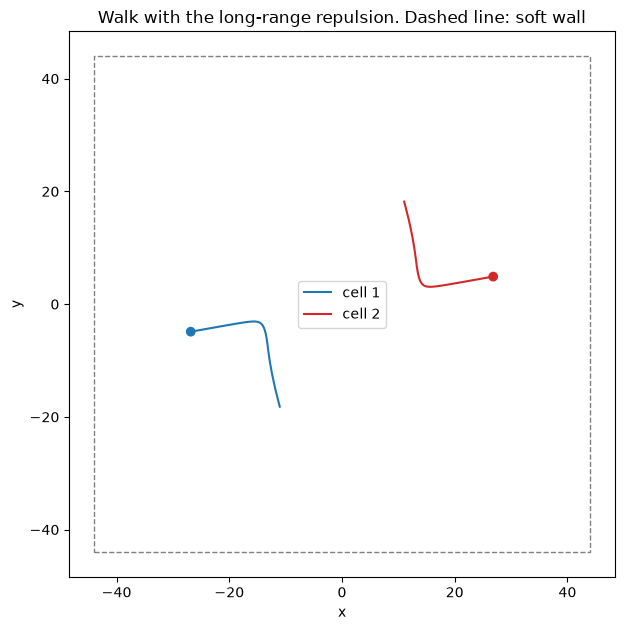

minimum separation during the walk: 28.90


In [15]:
fig, ax = plt.subplots(figsize=(6.4, 6.4))
ax.plot(walk["x1"], walk["y1"], color="tab:blue", label="cell 1")
ax.plot(walk["x2"], walk["y2"], color="tab:red", label="cell 2")
ax.scatter([walk["x1"][0], walk["x2"][0]], [walk["y1"][0], walk["y2"][0]],
           c=["tab:blue", "tab:red"], zorder=3)
box = L / 2 - wall_margin
ax.plot([-box, box, box, -box, -box], [-box, -box, box, box, -box],
        "--", color="gray", lw=1)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Walk with the long-range repulsion. Dashed line: soft wall")
ax.legend()
fig.tight_layout()
fig.savefig("two_cell_scattering_media/walk_path.png", dpi=140)
plt.show()
print(f"minimum separation during the walk: "
      f"{np.min(np.hypot(walk['x2'] - walk['x1'], walk['y2'] - walk['y1'])):.2f}")

In [16]:
# the walk frames also carry the phase names; save_video expects six fields
walk_video_frames = [f[:7] for f in walk_frames]
walk_video = save_video(
    walk_video_frames, "two_cell_scattering_media/two_cell_walk_scattering.mp4",
    "two-cell walk, long-range repulsion",
    xlim=(-L / 2, L / 2), ylim=(-L / 2, L / 2), seconds=5.0)
Video(walk_video, embed=True, width=480)

saved two_cell_scattering_media/two_cell_walk_scattering.mp4: 20 frames, 4 fps, 5.0 s


# 10. What this does and does not claim

- **The cells miss when the long-range piece is on and the approach is offset, and they meet when it is off.** Same initial condition. With $k_{\rm soft}=15$ the closest approach is 36.8 against a contact distance of 26, and the overlap stays at 0. With $k_{\rm soft}=0$ the closest approach is 18.3, the overlap peaks at 3.9, and the headings rotate by about 16°. The contact term was not retuned. On that contact the integrated rigid rotation is 1.9°, so most of the 16° is still the shared flow and the anchoring, as in the previous notebook.
- **The heading change on a miss is anchoring, not a rigid spin.** The headings turn by 35°. $\int\omega\,dt$ from $\tau=\xi_{\rm rot}\omega$ over the same run is 0.28° ($\xi_{\rm rot}=5.1\times 10^{4}$ for these cells). Switching $\beta$ off cuts the heading change to 0.4° and the cells still miss. The rigid term is kept, because it is the angular balance this model actually has. It is not amplified to make the figure look like a rigid-body collision.
- **Head-on does not invent a torque.** The peak torque is $10^{-6}$. The centres come in to 28.7 and recede, with no overlap. $|\langle\mathbf P\rangle|$ falls from 1 to 0.06 while the local $\langle|\mathbf P|\rangle$ dips to about 0.67 and recovers to 0.85: the mean heading loses coherence under the load. That is not a rotation, and it is not a finished reversal into a new crawl.
- **A smaller cell is deflected more.** Cell 2 grown at $R=9$ has $q_2=0.50$ against $q_1=1.02$, and its heading turns by 45° where the larger cell turns by 12°. Doubling one cell's charge at fixed shape doubles the force on *both* cells (11.7 to 23.4). Equal and opposite, then the lighter cell moves more.
- **A collision, when one happens, is the previous collision.** Shared Stokes solve, the same $k_{\rm rep}$, no merging, and the same redirect rule in the walk. In the walk itself, with this repulsion, the opening approach misses (closest 28.9, overlap 0, the trigger never fires) and the paths bend apart while both cells are still in their move phase. No restitution coefficient and no stored angular momentum were added: the substrate is a momentum sink, as it already was for the linear force.
- **$\lambda=8$ and $k_{\rm soft}=15$ are a choice of range and strength**, picked so the two regimes are both visible. A weaker long-range piece, or a smaller offset, moves the miss back toward the collision.